# Topic 4 Lab — LearnPath Data Quality and Responsible Data Practices
**Input (from Week 3):** `prepared_table.csv` (20 records, 17 columns) + `week3_manifest.json`. Upload both to `/content/`.
**Outputs:** `prepared_table_clean.csv`, `prepared_chunks_clean.jsonl`, `chunks_clean.pkl`, `docs/week4_validation_failures.csv`, `docs/week4_duplicate_review.csv`, `docs/week4_coverage_by_source.png`.
Note: LearnPath's Week 3 hand-off is a table of resource records, not text chunks, so the checks below run per record.

## A0 — Quality gate plan (replace requirement wording with your Topic 2 text)
| Topic 2 requirement | Required data/evidence | Quality concern | Observable check | Decision |
|---|---|---|---|---|
| Match resources to topic AND level | `primary_domain`, `difficulty_level` present, from a controlled vocabulary, consistent with `prerequisites` | Completeness + consistency + accuracy | values in allowed set; beginner records do not demand prior experience | Accept / Review / Hold |
| Show why a resource was picked; free and current only | `provider`, `resource_url`, `source_page_url`, `access_type`, `date_verified`, `verification_status` | Completeness + timeliness + accuracy | URLs well-formed; access_type free; date_verified within window; status verified | Accept / Quarantine / Hold |
| Your own: ___ | ___ | ___ | ___ | ___ |

In [ ]:
# Cell 1 — setup and Week 3 hand-off verification
!pip install -q pandera pandas matplotlib
import os, re, json, pickle, hashlib
from datetime import datetime, timezone
from difflib import SequenceMatcher
import pandas as pd
import matplotlib.pyplot as plt
import pandera.pandas as pa

PREPARED = '/content/prepared_table.csv'
MANIFEST = '/content/week3_manifest.json'
df = pd.read_csv(PREPARED)

with open(MANIFEST) as f:
    manifest = json.load(f)
sha = hashlib.sha256(open(PREPARED,'rb').read()).hexdigest()
print('Records:', len(df), '| manifest record_count:', manifest['record_count'])
print('SHA matches manifest:', sha == manifest['prepared_sha256'])
if len(df) != manifest['record_count'] or sha != manifest['prepared_sha256']:
    raise ValueError('Week 3 hand-off mismatch: file differs from manifest. Re-export from Week 3.')
print('Hand-off verified.'); print(df.columns.tolist())

Records: 20 | manifest record_count: 20
SHA matches manifest: True
Hand-off verified.
['resource_id', 'title', 'description', 'primary_domain', 'subtopics', 'resource_type', 'difficulty_level', 'learning_objectives', 'prerequisites', 'provider', 'resource_url', 'access_type', 'language', 'source_page_url', 'date_verified', 'verification_status', 'notes']


In [ ]:
# Cell 2 — quality inventory: missing / placeholder / noisy / inconsistent / stale
PLACEHOLDERS = {'', 'n/a', 'na', 'none', 'null', 'unknown', 'tbd', '-'}
def blank(s): return s.astype(str).str.strip().str.lower().isin(PLACEHOLDERS) | s.isna()

df['text'] = (df['title'].fillna('') + '. ' + df['description'].fillna('') + ' ' + df['learning_objectives'].fillna('')).str.strip()
df['desc_len'] = df['description'].fillna('').str.strip().str.len()
q = pd.DataFrame({'resource_id': df['resource_id']})
for col in ['title','description','provider','resource_url','source_page_url','difficulty_level','primary_domain','prerequisites','access_type','language','date_verified']:
    q['blank_'+col] = blank(df[col])
q['bad_char'] = df['text'].str.contains('\x00|\ufffd', regex=True)
q['noisy_ws'] = df['text'].str.contains(r'\n{3,}| {3,}', regex=True)
q['bad_url'] = ~df['resource_url'].astype(str).str.match(r'^https?://\S+$')
q['bad_source_url'] = ~df['source_page_url'].astype(str).str.match(r'^https?://\S+$')
dv = pd.to_datetime(df['date_verified'], errors='coerce')
q['bad_date'] = dv.isna()
STALE_DAYS = 180   # CHANGE and justify
age = (pd.Timestamp.now() - dv).dt.days
q['stale'] = age > STALE_DAYS
q['not_verified'] = df['verification_status'].astype(str).str.lower().ne('verified')
print(q.drop(columns='resource_id').sum().to_string())
print(df['desc_len'].describe())
for c in ['difficulty_level','resource_type','access_type','language','verification_status','primary_domain']:
    print('\n', c); print(df[c].value_counts(dropna=False).to_string())

blank_title                0
blank_description          0
blank_provider             0
blank_resource_url         0
blank_source_page_url      0
blank_difficulty_level     0
blank_primary_domain       0
blank_prerequisites        0
blank_access_type          0
blank_language             0
blank_date_verified        0
bad_char                   0
noisy_ws                   0
bad_url                    0
bad_source_url             0
bad_date                   0
stale                      0
not_verified              20
count     20.000000
mean      78.800000
std       12.547174
min       61.000000
25%       69.000000
50%       76.000000
75%       88.000000
max      103.000000
Name: desc_len, dtype: float64

 difficulty_level
difficulty_level
beginner        16
intermediate     4

 resource_type
resource_type
course           13
tutorial          3
book              2
documentation     2

 access_type
access_type
free    20

 language
language
English    20

 verification_status
verificati

In [ ]:
# Cell 3 — manual inspection: read EVERY record (only 20) and look for issues rules can't catch
pd.set_option('display.max_colwidth', None)
for _, r in df.iterrows():
    print('---', r.resource_id, '|', r.title, '|', r.primary_domain, '|', r.difficulty_level)
    print('desc:', r.description); print('prereq:', r.prerequisites, '| access:', r.access_type, '| verified:', r.date_verified, r.verification_status)

--- LP0001 | The Python Tutorial | python_programming | intermediate
desc: Official tutorial on Python syntax, data structures, modules and classes.
prereq: Some programming experience expected. | access: free | verified: 2026-11-11 needs_review
--- LP0002 | Google's Python Class | python_programming | beginner
desc: Free class with written lessons, lecture videos and coding exercises.
prereq: Some programming experience. | access: free | verified: 2026-11-11 needs_review
--- LP0003 | Python for Everybody | python_programming | beginner
desc: Introductory Python course and open textbook covering programming, data structures and web data.
prereq: Beginner-oriented. | access: free | verified: 2026-11-11 needs_review
--- LP0004 | Automate the Boring Stuff with Python | python_programming | beginner
desc: Practical online book teaching Python through everyday automation tasks.
prereq: Beginner-oriented. | access: free | verified: 2026-11-11 needs_review
--- LP0005 | Think Python | python_p

### A3 — Observations (observation != conclusion; verify against the source page before deciding)
Starting points from your Week 3 output to check, not conclusions:
- LP0002 is labelled `beginner` but its prerequisites say "Some programming experience." Is the level label consistent with the prerequisite?
- Compare each `difficulty_level` against `prerequisites` and `description` across all 20 records.

| Observation | Classification / concern | Evidence needed | Decision |
|---|---|---|---|
| | | | |
| | | | |

**Reflection:** which issue (e.g. level label vs prerequisite wording, or whether a "free" resource really is free) is hard to express as a numeric/format rule? Which quality dimension is affected, and why would an automated check miss it?

In [ ]:
# Cell 4 — Pandera validation rules (>= 3 required). Choose thresholds from evidence.
MIN_DESC = 40   # CHANGE after looking at df['desc_len'].describe()
ALLOWED_LEVELS  = {'beginner','intermediate','advanced'}
ALLOWED_DOMAINS = {'python_programming','data_analysis','introductory_ml'}

schema = pa.DataFrameSchema({
    'resource_id': pa.Column(str, [pa.Check(lambda s: s.str.strip().str.len() > 0, error='resource_id empty'),
                                   pa.Check(lambda s: ~s.duplicated(), error='duplicate resource_id')]),
    'description': pa.Column(str, pa.Check(lambda s: s.str.strip().str.len() >= MIN_DESC, error=f'description shorter than {MIN_DESC}')),
    'resource_url': pa.Column(str, [pa.Check(lambda s: s.str.match(r'^https?://\S+$'), error='malformed resource_url'),
                                    pa.Check(lambda s: ~s.duplicated(), error='duplicate resource_url')]),
    'difficulty_level': pa.Column(str, pa.Check.isin(list(ALLOWED_LEVELS), error='level outside vocabulary')),
    'primary_domain': pa.Column(str, pa.Check.isin(list(ALLOWED_DOMAINS), error='domain outside vocabulary')),
}, strict=False)

try:
    schema.validate(df, lazy=True); failure_cases = pd.DataFrame(); print('All schema rules passed.')
except pa.errors.SchemaErrors as exc:
    failure_cases = exc.failure_cases.copy()
    print(failure_cases[['column','check','failure_case','index']])
os.makedirs('/content/docs', exist_ok=True)
failure_cases.to_csv('/content/docs/week4_validation_failures.csv', index=False)

# Rules that are warnings/review, not hard fails
df['flag_level_prereq'] = (df['difficulty_level'].str.lower()=='beginner') & df['prerequisites'].str.contains('experience', case=False, na=False)
df['flag_not_free'] = ~df['access_type'].str.contains('free', case=False, na=False)
df['flag_stale'] = q['stale']; df['flag_not_verified'] = q['not_verified']
summary = pd.DataFrame({
  'rule': ['description >= MIN_DESC','resource_url well-formed','resource_url unique','level in vocabulary','domain in vocabulary',
           'beginner w/ experience prerequisite (review)','access_type not free (review)',f'date_verified > {STALE_DAYS}d (warn)','status != verified (warn)'],
  'failures': [(df.desc_len<MIN_DESC).sum(), q.bad_url.sum(), df.resource_url.duplicated().sum(), (~df.difficulty_level.isin(ALLOWED_LEVELS)).sum(),
               (~df.primary_domain.isin(ALLOWED_DOMAINS)).sum(), df.flag_level_prereq.sum(), df.flag_not_free.sum(), df.flag_stale.sum(), df.flag_not_verified.sum()]})
summary['percent'] = (summary.failures/len(df)*100).round(1)
print(summary.to_string(index=False))

All schema rules passed.
                                        rule  failures  percent
                     description >= MIN_DESC         0      0.0
                    resource_url well-formed         0      0.0
                         resource_url unique         0      0.0
                         level in vocabulary         0      0.0
                        domain in vocabulary         0      0.0
beginner w/ experience prerequisite (review)         1      5.0
               access_type not free (review)         0      0.0
                 date_verified > 180d (warn)         0      0.0
                   status != verified (warn)        20    100.0


### A4 — Rule table (copy numbers from Cell 4)
| Rule | Condition | Failure detected / why this threshold | Failures | Decision |
|---|---|---|---|---|
| Description present/useful | len >= N | | | |
| URL well-formed + unique | regex, no repeats | | | |
| Level/domain in vocabulary | isin(allowed) | | | |
| Level vs prerequisite (project) | beginner w/o experience prerequisite | | | Review |

### A5 — Triage (inspect >= 3 flagged records)
| Failed item | Rule | Evidence checked | Interpretation (defect / valid exception / uncertain) | Decision | Reason |
|---|---|---|---|---|---|
| | | | | | |

> Validation detects a condition. Engineering judgement determines the action. Note: format validity of a URL does not prove the link is live or the content is still free.

In [ ]:
# Cell 5 — duplicates (exact + URL + near-duplicate titles), provenance preserved
content_cols = [c for c in df.columns if c in ['title','description','primary_domain','provider','resource_url']]
def norm(s): return re.sub(r'\s+',' ', str(s).strip().lower())
df['_hash'] = df[content_cols].apply(lambda r: hashlib.sha256('|'.join(norm(v) for v in r).encode()).hexdigest(), axis=1)
dups = []
for h, g in df.groupby('_hash'):
    if len(g) > 1: dups.append({'type':'exact','ids':list(g.resource_id),'note':'identical content'})
for u, g in df.groupby(df.resource_url.map(norm)):
    if len(g) > 1: dups.append({'type':'same_url','ids':list(g.resource_id),'note':u})
titles = df.set_index('resource_id')['title'].map(norm).to_dict()
ids = list(titles)
for i in range(len(ids)):
    for j in range(i+1, len(ids)):
        r = SequenceMatcher(None, titles[ids[i]], titles[ids[j]]).ratio()
        if r > 0.85: dups.append({'type':'near_title','ids':[ids[i],ids[j]],'note':f'similarity {r:.2f}'})
dup_df = pd.DataFrame(dups); print(dup_df if len(dup_df) else 'No exact, URL or near-title duplicates found.')
dup_df.to_csv('/content/docs/week4_duplicate_review.csv', index=False)
# Same-title-different-provider or different-version cases need MANUAL review; hashing cannot prove semantic uniqueness.

No exact, URL or near-title duplicates found.


In [ ]:
# Cell 6 — build the reviewed corpus. EDIT `remove_ids`/`quarantine_ids` to match YOUR A5 decisions.
remove_ids, quarantine_ids = [], []     # e.g. ['LP0007'] — leave empty if triage found nothing to remove
clean = df[~df.resource_id.isin(remove_ids + quarantine_ids)].drop(columns=['_hash'])
if quarantine_ids:
    df[df.resource_id.isin(quarantine_ids)].to_csv('/content/docs/week4_quarantine.csv', index=False)
os.makedirs('/content/data', exist_ok=True)
meta_cols = [c for c in clean.columns if c not in ['text','desc_len'] and not c.startswith('flag_')]
records = [{'chunk_id': i, 'text': r['text'], 'metadata': {c: r[c] for c in meta_cols}} for i, (_, r) in enumerate(clean.iterrows())]
clean[meta_cols].to_csv('/content/data/prepared_table_clean.csv', index=False)
with open('/content/data/prepared_chunks_clean.jsonl','w',encoding='utf-8') as f:
    for rec in records: f.write(json.dumps(rec, ensure_ascii=False, default=str)+'\n')
with open('/content/data/chunks_clean.pkl','wb') as f: pickle.dump(records, f)
print('Before:', len(df), '| After:', len(clean), '| removed:', remove_ids, '| quarantined:', quarantine_ids)

Before: 20 | After: 20 | removed: [] | quarantined: []


## B2 — Coverage against scope (define BEFORE reading the chart)
| Required area | Why needed | Expected evidence | Actual evidence | Potential gap? |
|---|---|---|---|---|
| Beginner resources in each domain | Core use case (topic + level) | at least some per domain | | |
| Mix of resource types (docs, tutorials, courses) | Requirement for docs/tutorials | | | |
| Your area: ___ | | | | |

With 20 records, a count difference is a signal to investigate, not proof of a gap.

primary_domain
introductory_ml       8
python_programming    6
data_analysis         6 

difficulty_level    beginner  intermediate
primary_domain                            
data_analysis              6             0
introductory_ml            5             3
python_programming         5             1 

provider
Kaggle                                 3
Google                                 2
Udacity                                2
Python Software Foundation             1
Allen B. Downey                        1
Harvard University                     1
University of Michigan / PY4E          1
Al Sweigart                            1
NumPy community                        1
pandas development team                1
Paul Walsh                             1
scikit-learn developers                1
Inria / scikit-learn contributors      1
Microsoft                              1
University of Helsinki / MinnaLearn    1
California Institute of Technology     1 

resource_type
course       

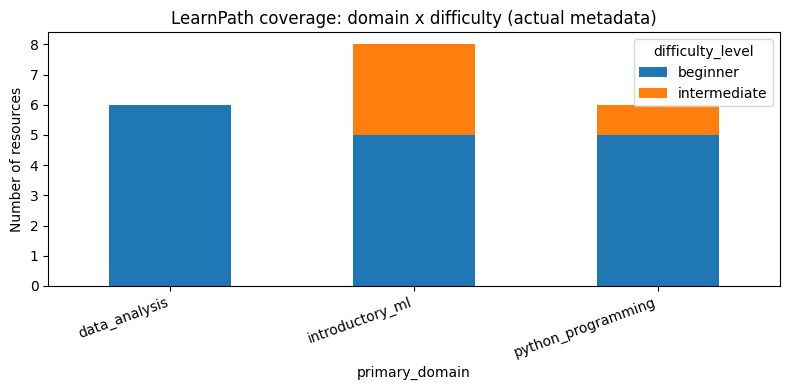

In [ ]:
# Cell 7 — coverage: domain, domain x level, provider, type, language
print(clean.primary_domain.value_counts().to_string(), '\n')
print(pd.crosstab(clean.primary_domain, clean.difficulty_level), '\n')
print(clean.provider.value_counts().to_string(), '\n')
print(clean.resource_type.value_counts().to_string(), '\n')
print(clean.language.value_counts().to_string())
cov = pd.crosstab(clean.primary_domain, clean.difficulty_level)
cov.plot(kind='bar', stacked=True, figsize=(8,4)); plt.ylabel('Number of resources')
plt.title('LearnPath coverage: domain x difficulty (actual metadata)'); plt.xticks(rotation=20, ha='right'); plt.tight_layout()
plt.savefig('/content/docs/week4_coverage_by_source.png'); plt.show()

## B3 — Bias risks and propagation (claim only what the data shows; say "potential representation risk")
| Bias type | Evidence (from Cell 7) | Likely origin | Downstream impact | Mitigation | Test (Topic 8) |
|---|---|---|---|---|---|
| Historical | e.g. which providers/languages exist as free resources | source landscape | | | |
| Representation | e.g. provider concentration, language mix, levels per domain | source selection (first 20 resources) | | | |
| Measurement | e.g. `difficulty_level` assigned by provider/author, not learner outcomes | proxy label | | | |

Propagation path to write for each: Source/Pipeline decision -> Prepared table -> Retrieval opportunity -> User-facing effect.

## B4 — Governance (use docs/week3_data_inventory.md and the Week 3 manifest)
Your manifest records access as "Free resources; individual licence terms require review" with status `needs_review`. That is an open governance item to carry forward.
| Question | Evidence | Status | Action / owner |
|---|---|---|---|
| Source owner, version/date, provenance traceable? | provider, source_page_url, date_verified | | |
| Rights/licence known and suitable? (publicly accessible != public domain) | manifest note | To verify | |
| Unnecessary personal data? | metadata is resource-level | | |
| Consent/collection basis (if personal data)? | | N/A? | |
| Update/removal/retention responsibility defined? | | | |

In [ ]:
# Cell 8 — pre-commit verification
with open('/content/data/chunks_clean.pkl','rb') as f: pk = pickle.load(f)
with open('/content/data/prepared_chunks_clean.jsonl', encoding='utf-8') as f: js = [json.loads(l) for l in f if l.strip()]
assert len(pk) == len(js) == len(pd.read_csv('/content/data/prepared_table_clean.csv')), 'clean outputs disagree'
print('Clean corpus verified:', len(pk), 'records')

Clean corpus verified: 20 records
